In [82]:
import time
import logging
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sqlalchemy import create_engine, inspect
from scipy.stats import ttest_ind
import scipy.stats as stats
warnings.filterwarnings("ignore")
from pathlib import Path


In [18]:
# Create database connection
engine = create_engine("sqlite:///inventory.db")

In [ ]:
DATA_DIR = Path("Data")
LOG_DIR = Path("logs")

In [20]:
# Create logs directory if it doesn't exist
import os

for file in os.listdir("Data"):
    if file.endswith(".csv"):
        print(file)

begin_inventory.csv
end_inventory.csv
purchase.csv
purchases .csv
purchase_prices.csv
sales.csv
vendor_invoice.csv


In [22]:
import os
import logging

# Create logs directory if it doesn't exist
os.makedirs("logs", exist_ok=True)

# Configure logging
logging.basicConfig(
    filename="logs/ingestion_db.log",
    level=logging.DEBUG,
    format="%(asctime)s - %(levelname)s - %(message)s",
    filemode="a"
)

logging.info("Logging started successfully")

In [71]:
# Check files available in Data folder
for file in os.listdir("Data"):
    print(file)


.ipynb_checkpoints
begin_inventory.csv
end_inventory.csv
purchase.csv
purchases .csv
purchase_prices.csv
sales.csv
vendor_invoice.csv


In [ ]:
import time
import logging
import pandas as pd
from pathlib import Path

DATA_DIR = Path("Data")
def ingest_db(df: pd.DataFrame, table_name: str) -> None:
    """Write a DataFrame to a database table."""
    df.to_sql(table_name, con=engine, if_exists="replace", index=False)


def load_raw_data() -> None:
    """Load CSV files from Data and ingest them into the database."""
    start = time.time()

    for file_path in DATA_DIR.glob("*.csv"):
        df = pd.read_csv(file_path)
        table_name = file_path.stem
        logging.info("Ingesting %s into the database", file_path.name)
        ingest_db(df, table_name)

    total_time = (time.time() - start) / 60
    logging.info("--------------------- ingestion complete --------------------")
    logging.info("Total time taken: %.2f minutes", total_time)


if __name__ == "__main__":
    load_raw_data()


In [23]:
from sqlalchemy import inspect

inspector = inspect(engine)
quote = engine.dialect.identifier_preparer.quote

for table in inspector.get_table_names():
    quoted_table = quote(table)
    count = pd.read_sql_query(
        f"SELECT COUNT(*) AS count FROM {quoted_table}",
        engine,
    ).iloc[0]["count"]
    print(f"{table}: {count} rows")

begin_inventory: 206529 rows
end_inventory: 224489 rows
purchase: 2372474 rows
purchase_prices: 12261 rows
purchases : 2372474 rows
sales: 12825363 rows
vendor_invoice: 5543 rows


In [29]:
from sqlalchemy import inspect

for table in inspect(engine).get_table_names():
    quoted_table = engine.dialect.identifier_preparer.quote(table)

    print("-" * 50, table, "-" * 50)

    count = pd.read_sql_query(
        f"SELECT COUNT(*) AS count FROM {quoted_table}",
        engine,
    )["count"].iloc[0]
    print("Count of records:", count)

    display(pd.read_sql_query(
        f"SELECT * FROM {quoted_table} LIMIT 5",
        engine,
    ))

-------------------------------------------------- begin_inventory --------------------------------------------------
Count of records: 206529


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,startDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,8,12.99,2024-01-01
1,1_HARDERSFIELD_60,1,HARDERSFIELD,60,Canadian Club 1858 VAP,750mL,7,10.99,2024-01-01
2,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,6,36.99,2024-01-01
3,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,3,38.99,2024-01-01
4,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,6,34.99,2024-01-01


-------------------------------------------------- end_inventory --------------------------------------------------
Count of records: 224489


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,endDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,11,12.99,2024-12-31
1,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,7,36.99,2024-12-31
2,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,7,38.99,2024-12-31
3,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,4,34.99,2024-12-31
4,1_HARDERSFIELD_75,1,HARDERSFIELD,75,Three Olives Tomato Vodka,750mL,7,14.99,2024-12-31


-------------------------------------------------- purchase_prices --------------------------------------------------
Count of records: 12261


,Brand,Description,Price,Size,Volume,Classification,PurchasePrice,VendorNumber,VendorName
0,58,Gekkeikan Black & Gold Sake,12.99,750mL,750,1,9.28,8320,SHAW ROSS INT L IMP LTD
1,62,Herradura Silver Tequila,36.99,750mL,750,1,28.67,1128,BROWN-FORMAN CORP
2,63,Herradura Reposado Tequila,38.99,750mL,750,1,30.46,1128,BROWN-FORMAN CORP
3,72,No. 3 London Dry Gin,34.99,750mL,750,1,26.11,9165,ULTRA BEVERAGE COMPANY LLP
4,75,Three Olives Tomato Vodka,14.99,750mL,750,1,10.94,7245,PROXIMO SPIRITS INC.


... (2 outputs left out)

-------------------------------------------------- sales --------------------------------------------------
Count of records: 12825363


,InventoryId,Store,Brand,Description,Size,SalesQuantity,SalesDollars,SalesPrice,SalesDate,Volume,Classification,ExciseTax,VendorNo,VendorName
0,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2024-01-01,750.0,1,0.79,12546,JIM BEAM BRANDS COMPANY
1,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,2,32.98,16.49,2024-01-02,750.0,1,1.57,12546,JIM BEAM BRANDS COMPANY
2,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2024-01-03,750.0,1,0.79,12546,JIM BEAM BRANDS COMPANY
3,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,14.49,14.49,2024-01-08,750.0,1,0.79,12546,JIM BEAM BRANDS COMPANY
4,1_HARDERSFIELD_1005,1,1005,Maker's Mark Combo Pack,375mL 2 Pk,2,69.98,34.99,2024-01-09,375.0,1,0.79,12546,JIM BEAM BRANDS COMPANY


-------------------------------------------------- vendor_invoice --------------------------------------------------
Count of records: 5543


,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None


In [30]:
purchase_prices = pd.read_sql_query(""" select*from purchase_prices where VendorNumber = 4466""",engine)
purchase_prices

,Brand,Description,Price,Size,Volume,Classification,PurchasePrice,VendorNumber,VendorName
0,5215,TGI Fridays Long Island Iced,12.99,1750mL,1750,1,9.41,4466,AMERICAN VINTAGE BEVERAGE
1,5255,TGI Fridays Ultimte Mudslide,12.99,1750mL,1750,1,9.35,4466,AMERICAN VINTAGE BEVERAGE
2,3140,TGI Fridays Orange Dream,14.99,1750mL,1750,1,11.19,4466,AMERICAN VINTAGE BEVERAGE


In [32]:
vendor_invoice = pd.read_sql_query(""" select * from vendor_invoice where VendorNumber =4466 """,engine)
vendor_invoice

,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-19,8207,2023-12-27,2024-02-26,335,3142.33,16.97,None
2,4466,AMERICAN VINTAGE BEVERAGE,2024-01-18,8307,2024-01-03,2024-02-18,41,383.35,1.99,None
3,4466,AMERICAN VINTAGE BEVERAGE,2024-01-27,8469,2024-01-14,2024-03-11,72,673.20,3.30,None
4,4466,AMERICAN VINTAGE BEVERAGE,2024-02-04,8532,2024-01-19,2024-03-15,79,740.21,3.48,None
5,4466,AMERICAN VINTAGE BEVERAGE,2024-02-09,8604,2024-01-24,2024-03-15,347,3261.37,17.61,None
6,4466,AMERICAN VINTAGE BEVERAGE,2024-02-17,8793,2024-02-05,2024-04-02,72,675.36,3.17,None
7,4466,AMERICAN VINTAGE BEVERAGE,2024-03-01,8892,2024-02-12,2024-03-28,117,1096.05,5.15,None
8,4466,AMERICAN VINTAGE BEVERAGE,2024-03-07,8995,2024-02-19,2024-04-02,129,1209.27,5.44,None
9,4466,AMERICAN VINTAGE BEVERAGE,2024-03-12,9033,2024-02-22,2024-04-16,147,1377.87,6.61,None


In [33]:
sales =pd.read_sql_query("""select * from sales where VendorNo = 4466""",engine)
sales

,InventoryId,Store,Brand,Description,Size,SalesQuantity,SalesDollars,SalesPrice,SalesDate,Volume,Classification,ExciseTax,VendorNo,VendorName
0,1_HARDERSFIELD_5215,1,5215,TGI Fridays Long Island Iced,1.75L,1,12.99,12.99,2024-01-09,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
1,1_HARDERSFIELD_5215,1,5215,TGI Fridays Long Island Iced,1.75L,1,12.99,12.99,2024-01-12,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
2,1_HARDERSFIELD_5215,1,5215,TGI Fridays Long Island Iced,1.75L,1,12.99,12.99,2024-01-15,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
3,1_HARDERSFIELD_5215,1,5215,TGI Fridays Long Island Iced,1.75L,1,12.99,12.99,2024-01-21,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
4,1_HARDERSFIELD_5215,1,5215,TGI Fridays Long Island Iced,1.75L,1,12.99,12.99,2024-01-23,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9448,9_BLACKPOOL_5215,9,5215,TGI Fridays Long Island Iced,1.75L,1,12.99,12.99,2024-12-21,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
9449,9_BLACKPOOL_5255,9,5255,TGI Fridays Ultimte Mudslide,1.75L,1,12.99,12.99,2024-12-02,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
9450,9_BLACKPOOL_5255,9,5255,TGI Fridays Ultimte Mudslide,1.75L,1,12.99,12.99,2024-12-09,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
9451,9_BLACKPOOL_5255,9,5255,TGI Fridays Ultimte Mudslide,1.75L,1,12.99,12.99,2024-12-23,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE


In [8]:
tables = pd.read_sql_query("""
SELECT name
FROM sqlite_master
WHERE type='table'
""", engine)

print(tables)

              name
0  begin_inventory
1    end_inventory
2       purchases 
3  purchase_prices
4            sales
5   vendor_invoice


In [12]:
for table in tables['name']:
    print(table)

begin_inventory
end_inventory
purchases 
purchase_prices
sales
vendor_invoice


In [10]:
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    engine
)

print(tables)

              name
0  begin_inventory
1    end_inventory
2       purchases 
3  purchase_prices
4            sales
5   vendor_invoice


In [41]:
purchase_prices

,Brand,Description,Price,Size,Volume,Classification,PurchasePrice,VendorNumber,VendorName
0,5215,TGI Fridays Long Island Iced,12.99,1750mL,1750,1,9.41,4466,AMERICAN VINTAGE BEVERAGE
1,5255,TGI Fridays Ultimte Mudslide,12.99,1750mL,1750,1,9.35,4466,AMERICAN VINTAGE BEVERAGE
2,3140,TGI Fridays Orange Dream,14.99,1750mL,1750,1,11.19,4466,AMERICAN VINTAGE BEVERAGE


In [43]:
vendor_invoice['PONumber'].nunique()

55

In [46]:
vendor_invoice.columns

Index(['VendorNumber', 'VendorName', 'InvoiceDate', 'PONumber', 'PODate',
       'PayDate', 'Quantity', 'Dollars', 'Freight', 'Approval'],
      dtype='str')

In [ ]:
from sqlalchemy import create_engine

engine = create_engine("sqlite:///inventory.db")
purchase = pd.read_sql_query("SELECT * FROM purchase", engine)

In [49]:
sales.groupby('Brand')[['SalesDollars','SalesPrice','SalesQuantity']].sum()

,SalesDollars,SalesPrice,SalesQuantity
Brand,,,
3140,50531.10,30071.85,3890
5215,60416.49,41542.02,4651
5255,79187.04,51180.60,6096


In [5]:
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("sqlite:///inventory.db")

freight_summary = pd.read_sql_query("""
SELECT
    VendorNumber,
    VendorName,
    SUM(Freight) AS FreightCost
FROM vendor_invoice
GROUP BY VendorNumber, VendorName
""", engine)

print(freight_summary.head())

   VendorNumber                               VendorName  FreightCost
0             2  IRA GOLDMAN AND WILLIAMS, LLP                  27.08
1            54              AAPER ALCOHOL & CHEMICAL CO         0.48
2            60              ADAMBA IMPORTS INTL INC           367.52
3           105              ALTAMAR BRANDS LLC                 62.39
4           200              AMERICAN SPIRITS EXCHANGE           6.19


In [11]:
purchase = pd.read_sql_query(
    "SELECT * FROM purchase",
    engine
)
print(f"Columns: {purchase.shape[1]}")

Columns: 16


In [13]:
purchase.groupby(['Brand', 'PurchasePrice'])[['Quantity', 'Dollars']].sum()

,,Quantity,Dollars
Brand,PurchasePrice,,
58,9.28,3550,32944.00
60,7.40,1633,12084.20
61,10.60,312,3307.20
62,28.67,3200,91744.00
63,30.46,2855,86963.30
...,...,...,...
90089,77.92,32,2493.44
90090,448.27,6,2689.62
90604,78.42,118,9253.56


In [20]:
df = pd.read_sql_query("""
SELECT
    p.VendorNumber,
    p.VendorName,
    p.Brand,
    p.PurchasePrice,
    pp.Volume,
    pp.Price AS ActualPrice,
    SUM(p.Quantity) AS TotalPurchaseQuantity,
    SUM(p.Dollars) AS TotalPurchaseDollars
FROM purchase AS p
JOIN purchase_prices AS pp
    ON p.Brand = pp.Brand
    AND p.PurchasePrice = pp.Price
WHERE p.PurchasePrice > 0
GROUP BY
    p.VendorNumber,
    p.VendorName,
    p.Brand,
    p.PurchasePrice,
    pp.Volume,
    pp.Price
ORDER BY TotalPurchaseDollars DESC
""", engine)


In [29]:
df = pd.read_sql_query("""
SELECT
    VendorNo,
    Brand,
    SUM(SalesDollars) AS TotalSalesDollars,
    SUM(SalesPrice) AS TotalSalesPrice,
    SUM(SalesQuantity) AS TotalSalesQuantity
FROM sales
GROUP BY
    VendorNo,
    Brand
ORDER BY
    TotalSalesDollars DESC
""", engine)


In [74]:
# Check available columns
print(df.columns.tolist())

# Remove leading/trailing spaces from column names
df.columns = df.columns.str.strip()

# Calculate Discount Percentage
if "ActualPrice" in df.columns and "PurchasePrice" in df.columns:

    df["DiscountPct"] = (
        (df["ActualPrice"] - df["PurchasePrice"])
        / df["ActualPrice"]
        * 100
    ).round(2)

    top_discounts = (
        df.sort_values(by="DiscountPct", ascending=False)
          .loc[:, [
              "VendorNumber",
              "Brand",
              "ActualPrice",
              "PurchasePrice",
              "DiscountPct"
          ]]
          .head(10)
    )

    print(top_discounts)

else:
    print("Required columns not found.")
    print("Available columns:")
    print(df.columns.tolist())

['VendorNo', 'Brand', 'TotalSalesDollars', 'TotalSalesPrice', 'TotalSalesQuantity']
Required columns not found.
Available columns:
['VendorNo', 'Brand', 'TotalSalesDollars', 'TotalSalesPrice', 'TotalSalesQuantity']


In [ ]:
import time
import pandas as pd
# Start timer
start = time.time()
# Create final table
final_table = pd.read_sql_query("""
SELECT
pp.VendorNumber,
pp.Brand,
pp.Price AS ActualPrice,
pp.PurchasePrice,
 
SUM(s.SalesQuantity) AS TotalSalesQuantity,
SUM(s.SalesDollars) AS TotalSalesDollars,
SUM(s.SalesPrice) AS TotalSalesPrice,
SUM(s.ExciseTax) AS TotalExciseTax,
 
SUM(vi.Quantity) AS TotalPurchaseQuantity,
SUM(vi.Dollars) AS TotalPurchaseDollars,
SUM(vi.Freight) AS TotalFreightCost
 
FROM purchase_prices pp
 
LEFT JOIN sales s
ON pp.VendorNumber = s.VendorNo
AND pp.Brand = s.Brand
 
LEFT JOIN vendor_invoice vi
ON pp.VendorNumber = vi.VendorNumber
 
GROUP BY
pp.VendorNumber,
pp.Brand,
pp.Price,
pp.PurchasePrice
""", engine)
# End timer
end = time.time()
# Display results
print(f"Query execution time: {end - start:.2f} seconds")
print("\nShape of final table:")
print(final_table.shape)
print("\nFirst 5 rows:")
print(final_table.head())
Recommended Version (Pre-Aggregated to Avoid Duplicate Joins)
Python
import time
import pandas as pd
start = time.time()
final_table = pd.read_sql_query("""
WITH sales_summary AS (
SELECT
VendorNo,
Brand,
SUM(SalesQuantity) AS TotalSalesQuantity,
SUM(SalesDollars) AS TotalSalesDollars,
SUM(SalesPrice) AS TotalSalesPrice,
SUM(ExciseTax) AS TotalExciseTax
FROM sales
GROUP BY VendorNo, Brand
),
 
invoice_summary AS (
SELECT
VendorNumber,
SUM(Quantity) AS TotalPurchaseQuantity,
SUM(Dollars) AS TotalPurchaseDollars,
SUM(Freight) AS TotalFreightCost
FROM vendor_invoice
GROUP BY VendorNumber
)
 
SELECT
pp.VendorNumber,
pp.Brand,
pp.Price AS ActualPrice,
pp.PurchasePrice,
 
COALESCE(ss.TotalSalesQuantity, 0) AS TotalSalesQuantity,
COALESCE(ss.TotalSalesDollars, 0) AS TotalSalesDollars,
COALESCE(ss.TotalSalesPrice, 0) AS TotalSalesPrice,
COALESCE(ss.TotalExciseTax, 0) AS TotalExciseTax,
 
COALESCE(iv.TotalPurchaseQuantity, 0) AS TotalPurchaseQuantity,
COALESCE(iv.TotalPurchaseDollars, 0) AS TotalPurchaseDollars,
COALESCE(iv.TotalFreightCost, 0) AS TotalFreightCost
 
FROM purchase_prices pp
 
LEFT JOIN sales_summary ss
ON pp.VendorNumber = ss.VendorNo
AND pp.Brand = ss.Brand
 
LEFT JOIN invoice_summary iv
ON pp.VendorNumber = iv.VendorNumber
""", engine)
end = time.time()
print(f"Query execution time: {end - start:.2f} seconds")
print(final_table.head())

In [32]:
vendor_sales_summary = pd.read_sql_query("""
WITH FreightSummary AS (
    SELECT
        VendorNumber,
        SUM(Freight) AS FreightCost
    FROM vendor_invoice
    GROUP BY VendorNumber
),

PurchaseSummary AS (
    SELECT
        p.VendorNumber,
        p.VendorName,
        p.Brand,
        p.Description,
        p.PurchasePrice,
        pp.Price AS ActualPrice,
        pp.Volume,
        SUM(p.Quantity) AS TotalPurchaseQuantity,
        SUM(p.Dollars) AS TotalPurchaseDollars
    FROM purchase p
    LEFT JOIN purchase_prices pp
        ON p.Brand = pp.Brand
    GROUP BY
        p.VendorNumber,
        p.VendorName,
        p.Brand,
        p.Description,
        p.PurchasePrice,
        pp.Price,
        pp.Volume
),

SalesSummary AS (
    SELECT
        VendorNo,
        Brand,
        SUM(SalesQuantity) AS TotalSalesQuantity,
        SUM(SalesDollars) AS TotalSalesDollars,
        SUM(SalesPrice) AS TotalSalesPrice,
        SUM(ExciseTax) AS TotalExciseTax
    FROM sales
    GROUP BY VendorNo, Brand
)

SELECT
    ps.VendorNumber,
    ps.VendorName,
    ps.Brand,
    ps.Description,
    ps.PurchasePrice,
    ps.ActualPrice,
    ps.Volume,
    ps.TotalPurchaseQuantity,
    ps.TotalPurchaseDollars,
    ss.TotalSalesQuantity,
    ss.TotalSalesDollars,
    ss.TotalSalesPrice,
    ss.TotalExciseTax,
    fs.FreightCost
FROM PurchaseSummary ps
LEFT JOIN SalesSummary ss
    ON ps.VendorNumber = ss.VendorNo
   AND ps.Brand = ss.Brand
LEFT JOIN FreightSummary fs
    ON ps.VendorNumber = fs.VendorNumber
ORDER BY ps.TotalPurchaseDollars DESC
""", engine)

print(vendor_sales_summary.head())

   VendorNumber                   VendorName  Brand              Description  \
0          1128  BROWN-FORMAN CORP             1233  Jack Daniels No 7 Black   
1          4425        MARTIGNETTI COMPANIES   3405    Tito's Handmade Vodka   
2         17035  PERNOD RICARD USA             8068         Absolut 80 Proof   
3          3960  DIAGEO NORTH AMERICA INC      4261   Capt Morgan Spiced Rum   
4          3960  DIAGEO NORTH AMERICA INC      3545          Ketel One Vodka   

   PurchasePrice  ActualPrice Volume  TotalPurchaseQuantity  \
0          26.27        36.99   1750                 145080   
1          23.19        28.99   1750                 164038   
2          18.24        24.99   1750                 187407   
3          16.17        22.99   1750                 201682   
4          21.89        29.99   1750                 138109   

   TotalPurchaseDollars  TotalSalesQuantity  TotalSalesDollars  \
0            3811251.60            142049.0         5101919.51   
1       

In [33]:
import pandas as pd

vendor_sales_summary = pd.read_sql_query(
    "SELECT * FROM vendor_sales_summary",
    engine
)

print(vendor_sales_summary.dtypes)

VendorNumber               int64
VendorName                   str
Brand                      int64
Description                  str
PurchasePrice            float64
ActualPrice              float64
Volume                   float64
TotalPurchaseQuantity      int64
TotalPurchaseDollars     float64
TotalSalesQuantity       float64
TotalSalesDollars        float64
TotalSalesPrice          float64
TotalExciseTax           float64
FreightCost              float64
GrossProfit              float64
ProfitMargin             float64
StockTurnover            float64
SalesToPurchaseRatio     float64
dtype: object


In [67]:
missing_summary = pd.DataFrame({
    'MissingCount': vendor_sales_summary.isnull().sum(),
    'MissingPercentage': (
        vendor_sales_summary.isnull().sum()
        / len(vendor_sales_summary)
        * 100
    )
}).sort_values(by='MissingPercentage', ascending=False)

print(missing_summary)

                       MissingCount  MissingPercentage
VendorNumber                      0                NaN
VendorName                        0                NaN
Brand                             0                NaN
Description                       0                NaN
PurchasePrice                     0                NaN
ActualPrice                       0                NaN
Volume                            0                NaN
TotalPurchaseQuantity             0                NaN
TotalPurchaseDollars              0                NaN
TotalSalesQuantity                0                NaN
TotalSalesDollars                 0                NaN
TotalSalesPrice                   0                NaN
TotalExciseTax                    0                NaN
FreightCost                       0                NaN
AllocatedFreight                  0                NaN
GrossProfit                       0                NaN
ProfitMargin                      0                NaN
StockTurno

In [53]:
import pandas as pd

vendor_sales_summary = pd.read_sql_query("""
SELECT *
FROM vendor_sales_summary
""", engine)

vendor_sales_summary.head()

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,AllocatedFreight,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio


In [54]:
vendor_sales_summary['VendorName'].unique()

array([], dtype=object)

In [55]:
vendor_sales_summary['Description'].unique()

array([], dtype=object)

In [59]:
import pandas as pd

vendor_sales_summary.columns = vendor_sales_summary.columns.str.strip()

vendor_sales_summary['volume'] = pd.to_numeric(
    vendor_sales_summary['Volume'],
    errors='coerce'
).astype('float64')

print(vendor_sales_summary[['Volume', 'volume']].head())
print(vendor_sales_summary['volume'].dtype)

Empty DataFrame
Columns: [Volume, volume]
Index: []
float64


In [60]:
vendor_sales_summary.fillna(0,inplace=True)

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,AllocatedFreight,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio,volume


In [65]:
# Clean VendorName column
vendor_sales_summary['VendorName'] = (
    vendor_sales_summary['VendorName']
    .fillna('')
    .astype(str)
    .str.strip()
)

# Remove blank vendor names
vendor_sales_summary = vendor_sales_summary[
    vendor_sales_summary['VendorName'] != ''
]

print(vendor_sales_summary[['VendorName']].head())

Empty DataFrame
Columns: [VendorName]
Index: []


In [44]:
vendor_sales_summary['ProfitMargin'] = np.where(
    vendor_sales_summary['TotalSalesDollars'] > 0,
    (vendor_sales_summary['GrossProfit'] /
     vendor_sales_summary['TotalSalesDollars']) * 100,
    np.nan
)

,VendorName,GrossProfit,TotalSalesDollars,ProfitMargin
0,BROWN-FORMAN CORP,1290667.91,5101919.51,25.297693
1,MARTIGNETTI COMPANIES,1015032.27,4819073.49,21.062810
2,PERNOD RICARD USA,1119816.92,4538120.60,24.675786
3,DIAGEO NORTH AMERICA INC,1214774.94,4475972.88,27.139908
4,DIAGEO NORTH AMERICA INC,1199901.61,4223107.62,28.412764


In [45]:
# Most Profitable Vendors
vendor_sales_summary.sort_values(
    by='ProfitMargin',
    ascending=False
)[
    ['VendorName', 'ProfitMargin']
].head(10)

,VendorName,ProfitMargin
10649,MHW LTD,99.716657
10641,ULTRA BEVERAGE COMPANY LLP,99.604734
10561,DISARONNO INTERNATIONAL LLC,99.553246
10625,JIM BEAM BRANDS COMPANY,99.544844
10555,PERFECTA WINES,99.534226
10651,KOBRAND CORPORATION,99.393664
10533,PINE STATE TRADING CO,99.361349
10639,M S WALKER INC,99.348356
10565,MARTIGNETTI COMPANIES,99.343273
10275,ULTRA BEVERAGE COMPANY LLP,99.183564


In [43]:
vendor_sales_summary[
    [
        'VendorName',
        'GrossProfit',
        'TotalSalesDollars',
        'ProfitMargin'
    ]
].head()

,VendorName,GrossProfit,TotalSalesDollars,ProfitMargin
0,BROWN-FORMAN CORP,1290667.91,5101919.51,25.297693
1,MARTIGNETTI COMPANIES,1015032.27,4819073.49,21.062810
2,PERNOD RICARD USA,1119816.92,4538120.60,24.675786
3,DIAGEO NORTH AMERICA INC,1214774.94,4475972.88,27.139908
4,DIAGEO NORTH AMERICA INC,1199901.61,4223107.62,28.412764


In [41]:
vendor_sales_summary[
    [
        'VendorName',
        'TotalPurchaseQuantity',
        'TotalSalesQuantity',
        'StockTurnover'
    ]
].head()

,VendorName,TotalPurchaseQuantity,TotalSalesQuantity,StockTurnover
0,BROWN-FORMAN CORP,145080,142049.0,0.979108
1,MARTIGNETTI COMPANIES,164038,160247.0,0.976890
2,PERNOD RICARD USA,187407,187140.0,0.998575
3,DIAGEO NORTH AMERICA INC,201682,200412.0,0.993703
4,DIAGEO NORTH AMERICA INC,138109,135838.0,0.983556


In [40]:
vendor_sales_summary.sort_values(
    by='SalesToPurchaseRatio',
    ascending=False
)[[
    'VendorName',
    'TotalSalesDollars',
    'TotalPurchaseDollars',
    'SalesToPurchaseRatio'
]].head(10)

,VendorName,TotalSalesDollars,TotalPurchaseDollars,SalesToPurchaseRatio
10649,MHW LTD,2717.55,7.70,352.928571
10641,ULTRA BEVERAGE COMPANY LLP,2221.29,8.78,252.994305
10561,DISARONNO INTERNATIONAL LLC,4781.16,21.36,223.837079
10625,JIM BEAM BRANDS COMPANY,2368.42,10.78,219.705009
10555,PERFECTA WINES,4768.41,22.21,214.696533
10651,KOBRAND CORPORATION,1208.90,7.33,164.924966
10533,PINE STATE TRADING CO,3937.99,25.15,156.580119
10639,M S WALKER INC,1440.97,9.39,153.457934
10565,MARTIGNETTI COMPANIES,3148.95,20.68,152.270309
10275,ULTRA BEVERAGE COMPANY LLP,7878.14,64.32,122.483520


In [35]:
vendor_sales_summary.sort_values(
    'StockTurnover',
    ascending=False
)[['VendorName', 'StockTurnover']].head(10)

,VendorName,StockTurnover
10649,MHW LTD,274.5
10561,DISARONNO INTERNATIONAL LLC,171.0
10641,ULTRA BEVERAGE COMPANY LLP,171.0
10555,PERFECTA WINES,159.0
10625,JIM BEAM BRANDS COMPANY,158.0
10651,KOBRAND CORPORATION,110.0
10565,MARTIGNETTI COMPANIES,105.0
10639,M S WALKER INC,103.0
10533,PINE STATE TRADING CO,101.0
10691,PROXIMO SPIRITS INC.,86.0


In [ ]:
cursor = engine.cursor()

In [45]:
from sqlalchemy import create_engine, text

# Create database connection
engine = create_engine("sqlite:///inventory.db")

# Create table
with engine.connect() as engine:
    engine.execute(text("""
    CREATE TABLE IF NOT EXISTS vendor_sales_summary (
        VendorNumber INTEGER,
        VendorName VARCHAR(100),
        Brand INTEGER,
        Description VARCHAR(100),
        PurchasePrice DECIMAL(10,2),
        ActualPrice DECIMAL(10,2),
        Volume REAL,
        TotalPurchaseQuantity INTEGER,
        TotalPurchaseDollars DECIMAL(12,2),
        TotalSalesQuantity INTEGER,
        TotalSalesDollars DECIMAL(12,2),
        GrossProfit DECIMAL(12,2),
        ProfitMargin DECIMAL(10,2),
        StockTurnover DECIMAL(10,2)
    )
    """))
    engine.commit()

print("Table 'vendor_sales_summary' created successfully.")

Table 'vendor_sales_summary' created successfully.


In [46]:
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("sqlite:///inventory.db")

vendor_sales_summary = pd.read_sql_query(
    "SELECT * FROM vendor_sales_summary",
    engine
)

vendor_sales_summary.head()

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
0,1128,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750.0,145080,3811251.60,142049.0,5101919.51,672819.31,260999.20,68601.68,1290667.91,25.297693,0.979108,1.338647
1,4425,MARTIGNETTI COMPANIES,3405,Tito's Handmade Vodka,23.19,28.99,1750.0,164038,3804041.22,160247.0,4819073.49,561512.37,294438.66,144929.24,1015032.27,21.062810,0.976890,1.266830
2,17035,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750.0,187407,3418303.68,187140.0,4538120.60,461140.15,343854.07,123780.22,1119816.92,24.675786,0.998575,1.327594
3,3960,DIAGEO NORTH AMERICA INC,4261,Capt Morgan Spiced Rum,16.17,22.99,1750.0,201682,3261197.94,200412.0,4475972.88,420050.01,368242.80,257032.07,1214774.94,27.139908,0.993703,1.372493
4,3960,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750.0,138109,3023206.01,135838.0,4223107.62,545778.28,249587.83,257032.07,1199901.61,28.412764,0.983556,1.396897


In [27]:
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("sqlite:///inventory.db")

vendor_sales_summary = pd.read_sql_query(
    "SELECT * FROM vendor_sales_summary",
    engine
)

vendor_sales_summary.head()

vendor_sales_summary.to_sql(
    'vendor_sales_summary',
    engine,
    if_exists='replace',
    index=False
)

10692

In [29]:
import logging
import pandas as pd
from sqlalchemy import create_engine


# Configure logging
logging.basicConfig(
    filename="get_vendor_summary.log",
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s"
)


def create_vendor_summary(engine):
    """
    Merge purchase, sales, and vendor invoice tables
    to create a vendor summary.
    """

    query = """
    WITH FreightSummary AS (
        SELECT
            VendorNumber,
            SUM(Freight) AS FreightCost
        FROM vendor_invoice
        GROUP BY VendorNumber
    ),

    PurchaseSummary AS (
        SELECT
            p.VendorNumber,
            p.VendorName,
            p.Brand,
            p.Description,
            p.PurchasePrice,
            pp.Price AS ActualPrice,
            pp.Volume,
            SUM(p.Quantity) AS TotalPurchaseQuantity,
            SUM(p.Dollars) AS TotalPurchaseDollars
        FROM purchase p
        JOIN (
            SELECT
                Brand,
                MAX(Price) AS Price,
                MAX(Volume) AS Volume
            FROM purchase_prices
            GROUP BY Brand
        ) pp
            ON p.Brand = pp.Brand
        WHERE p.PurchasePrice > 0
        GROUP BY
            p.VendorNumber,
            p.VendorName,
            p.Brand,
            p.Description,
            p.PurchasePrice,
            pp.Price,
            pp.Volume
    ),

    SalesSummary AS (
        SELECT
            VendorNo,
            Brand,
            SUM(SalesQuantity) AS TotalSalesQuantity,
            SUM(SalesDollars) AS TotalSalesDollars,
            SUM(SalesPrice) AS TotalSalesPrice,
            SUM(ExciseTax) AS TotalExciseTax
        FROM sales
        GROUP BY VendorNo, Brand
    )

    SELECT
        ps.VendorNumber,
        ps.VendorName,
        ps.Brand,
        ps.Description,
        ps.PurchasePrice,
        ps.ActualPrice,
        ps.Volume,
        ps.TotalPurchaseQuantity,
        ps.TotalPurchaseDollars,
        COALESCE(ss.TotalSalesQuantity, 0) AS TotalSalesQuantity,
        COALESCE(ss.TotalSalesDollars, 0) AS TotalSalesDollars,
        COALESCE(ss.TotalSalesPrice, 0) AS TotalSalesPrice,
        COALESCE(ss.TotalExciseTax, 0) AS TotalExciseTax,
        COALESCE(fs.FreightCost, 0) AS FreightCost

    FROM PurchaseSummary ps

    LEFT JOIN SalesSummary ss
        ON ps.VendorNumber = ss.VendorNo
       AND ps.Brand = ss.Brand

    LEFT JOIN FreightSummary fs
        ON ps.VendorNumber = fs.VendorNumber

    ORDER BY ps.TotalPurchaseDollars DESC
    """

    vendor_sales_summary = pd.read_sql_query(query, engine)

    vendor_totals = (
        vendor_sales_summary.groupby("VendorNumber")[
            "TotalPurchaseDollars"
        ].transform("sum")
    )

    vendor_sales_summary["AllocatedFreight"] = (
        vendor_sales_summary["FreightCost"]
        * vendor_sales_summary["TotalPurchaseDollars"]
        / vendor_totals
    )

    return vendor_sales_summary


def clean_data(df):
    """
    Clean data and create derived metrics.
    """

    df = df.copy()

    # Convert volume to numeric
    df["Volume"] = pd.to_numeric(
        df["Volume"],
        errors="coerce"
    )

    # Fill missing values
    df.fillna(0, inplace=True)

    # Clean text columns
    df["VendorName"] = (
        df["VendorName"]
        .astype(str)
        .str.strip()
    )

    df["Description"] = (
        df["Description"]
        .astype(str)
        .str.strip()
    )

    # Calculate Gross Profit
    df["GrossProfit"] = (
        df["TotalSalesDollars"]
        - df["TotalPurchaseDollars"]
        - df["AllocatedFreight"]
    )

    # Calculate Profit Margin %
    df["ProfitMargin"] = (
        df["GrossProfit"]
        / df["TotalSalesDollars"].replace(0, pd.NA)
    ) * 100

    # Stock Turnover
    df["StockTurnover"] = (
        df["TotalSalesQuantity"]
        / df["TotalPurchaseQuantity"].replace(0, pd.NA)
    )

    # Sales-to-Purchase Ratio
    df["SalesToPurchaseRatio"] = (
        df["TotalSalesDollars"]
        / df["TotalPurchaseDollars"].replace(0, pd.NA)
    )

    return df


def main():

    engine = create_engine("sqlite:///inventory.db")

    try:
        logging.info("Creating Vendor Summary Table...")

        vendor_sales_summary = create_vendor_summary(engine)

        logging.info("Cleaning Data...")

        vendor_sales_summary = clean_data(
            vendor_sales_summary
        )

        logging.info("Saving Vendor Summary Table...")

        vendor_sales_summary.to_sql(
            "vendor_sales_summary",
            engine,
            if_exists="replace",
            index=False
        )

        logging.info(
            "Process completed successfully."
        )

        print(vendor_sales_summary.head())

    except Exception as e:
        logging.exception(
            f"Error occurred: {e}"
        )
        raise

    finally:
        engine.dispose()


if __name__ == "__main__":
    main()



Empty DataFrame
Columns: [VendorNumber, VendorName, Brand, Description, PurchasePrice, ActualPrice, Volume, TotalPurchaseQuantity, TotalPurchaseDollars, TotalSalesQuantity, TotalSalesDollars, TotalSalesPrice, TotalExciseTax, FreightCost, AllocatedFreight, GrossProfit, ProfitMargin, StockTurnover, SalesToPurchaseRatio]
Index: []


In [1]:
import logging
import pandas as pd
from sqlalchemy import create_engine


def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    """
    Clean vendor summary data.

    Steps:
    1. Remove duplicate rows
    2. Remove completely empty rows
    3. Remove rows with missing VendorName
    """

    df = df.copy()

    # Remove duplicates
    df.drop_duplicates(inplace=True)

    # Remove rows where all values are missing
    df.dropna(how="all", inplace=True)

    # Remove rows with missing VendorName
    if "VendorName" in df.columns:
        df.dropna(subset=["VendorName"], inplace=True)

    return df


def main() -> None:
    """
    Load, clean, and save vendor summary data.
    """

    engine = create_engine("sqlite:///inventory.db")

    try:
        # Display available tables
        logging.info("Checking available tables...")

        tables = pd.read_sql_query(
            """
            SELECT name
            FROM sqlite_master
            WHERE type = 'table'
            """,
            engine
        )

        logging.info("Available Tables:\n%s", tables)

        # Load vendor summary table
        logging.info("Loading vendor_sales_summary table...")

        df = pd.read_sql_query(
            """
            SELECT *
            FROM vendor_sales_summary
            """,
            engine
        )

        logging.info(
            "Loaded %s rows and %s columns",
            df.shape[0],
            df.shape[1]
        )

        # Clean data
        logging.info("Cleaning data...")

        clean_df = clean_data(df)

        logging.info(
            "Cleaned Data Preview:\n%s",
            clean_df.head()
        )

        # Save cleaned data
        logging.info(
            "Writing cleaned data back to database..."
        )

        clean_df.to_sql(
            name="vendor_sales_summary",
            con=engine,
            if_exists="replace",
            index=False
        )

        logging.info(
            "Data cleaning completed successfully. Final shape: %s",
            clean_df.shape
        )

        print("\nData cleaned successfully!")
        print(f"Final Shape: {clean_df.shape}")

    except Exception as e:
        logging.exception(
            "Failed to process vendor summary data: %s",
            str(e)
        )
        raise

    finally:
        engine.dispose()
        logging.info("Database connection closed.")


if __name__ == "__main__":

    logging.basicConfig(
        level=logging.INFO,
        format="%(asctime)s - %(levelname)s - %(message)s"
    )

    main()

2026-11-03 10:20:01,420 - INFO - Checking available tables...
2026-11-03 10:20:01,435 - INFO - Available Tables:
                   name
0            purchases 
1       purchase_prices
2                 sales
3        vendor_invoice
4       begin_inventory
5         end_inventory
6              purchase
7  vendor_sales_summary
2026-11-03 10:20:01,454 - INFO - Loading vendor_sales_summary table...
2026-11-03 10:20:01,457 - INFO - Loaded 0 rows and 19 columns
2026-11-03 10:20:01,458 - INFO - Cleaning data...
2026-11-03 10:20:01,463 - INFO - Cleaned Data Preview:
Empty DataFrame
Columns: [VendorNumber, VendorName, Brand, Description, PurchasePrice, ActualPrice, Volume, TotalPurchaseQuantity, TotalPurchaseDollars, TotalSalesQuantity, TotalSalesDollars, TotalSalesPrice, TotalExciseTax, FreightCost, AllocatedFreight, GrossProfit, ProfitMargin, StockTurnover, SalesToPurchaseRatio]
Index: []
2026-11-03 10:20:01,465 - INFO - Writing cleaned data back to database...
2026-11-03 10:20:01,489 - INF


Data cleaned successfully!
Final Shape: (0, 19)


In [48]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
VendorNo,11272.0,10665.149929,18745.417071,2.00,3960.00,7153.000,9552.0000,201359.00
Brand,11272.0,18018.312101,12651.743007,58.00,5835.25,18780.000,25257.2500,90631.00
TotalSalesDollars,11272.0,40104.946063,163544.192297,0.98,575.76,4308.705,25652.4775,5101919.51
TotalSalesPrice,11272.0,17852.498338,43970.935121,0.49,241.78,2291.280,14463.7775,672819.31
TotalSalesQuantity,11272.0,2920.322569,10688.651525,1.00,26.00,198.000,1728.0000,334939.00


In [45]:
import warnings
warnings.filterwarnings('ignore')
from sqlalchemy import create_engine
import pandas as pd

engine = create_engine("sqlite:///inventory.db")

tables = pd.read_sql_query(
    "SELECT name, type FROM sqlite_master ORDER BY type, name;",
    engine
)

print(tables)
from sqlalchemy import inspect

inspector = inspect(engine)

print("Views:")
print(inspector.get_view_names())

df = pd.read_sql_query(
    """
    SELECT *
    FROM vendor_sales_summary
    WHERE GrossProfit > 0
    """,
    engine
)

print(df.head())

                   name   type
0       begin_inventory  table
1         end_inventory  table
2              purchase  table
3       purchase_prices  table
4            purchases   table
5                 sales  table
6        vendor_invoice  table
7  vendor_sales_summary  table
Views:
[]
   VendorNumber                VendorName  Brand              Description  \
0          1128         BROWN-FORMAN CORP   1233  Jack Daniels No 7 Black   
1          4425     MARTIGNETTI COMPANIES   3405    Tito's Handmade Vodka   
2         17035         PERNOD RICARD USA   8068         Absolut 80 Proof   
3          3960  DIAGEO NORTH AMERICA INC   4261   Capt Morgan Spiced Rum   
4          3960  DIAGEO NORTH AMERICA INC   3545          Ketel One Vodka   

   PurchasePrice  ActualPrice  Volume  TotalPurchaseQuantity  \
0          26.27        36.99  1750.0                 145080   
1          23.19        28.99  1750.0                 164038   
2          18.24        24.99  1750.0                 18

In [46]:
from scipy.stats import ttest_ind

# Define thresholds
top_threshold = df["TotalSalesDollars"].quantile(0.85)
low_threshold = df["TotalSalesDollars"].quantile(0.15)

# Top vendors (high sales)
top_vendors = df[df["TotalSalesDollars"] >= top_threshold]["ProfitMargin"].dropna()

# Low vendors (low sales)
low_vendors = df[df["TotalSalesDollars"] <= low_threshold]["ProfitMargin"].dropna()

# Perform Welch's t-test
t_stat, p_value = ttest_ind(
    top_vendors,
    low_vendors,
    equal_var=False
)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Significant difference in profit margins.")
else:
    print("No significant difference in profit margins.")

T-statistic: -11.7633
P-value: 0.0000
Significant difference in profit margins.


In [47]:
#summary Statistics
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
VendorNumber,8564.0,NaN,NaN,NaN,10107.074965,17635.714818,2.0,3664.0,7153.0,9552.0,201359.0
VendorName,8564,119,MARTIGNETTI COMPANIES,1084,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Brand,8564.0,NaN,NaN,NaN,17614.670131,12946.130933,58.0,5375.75,17606.0,24935.25,90631.0
Description,8564,7707,Southern Comfort,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PurchasePrice,8564.0,NaN,NaN,NaN,21.780897,81.189624,0.36,6.66,10.06,17.85,3352.93
ActualPrice,8564.0,NaN,NaN,NaN,32.297467,112.420744,0.49,9.99,14.99,25.99,4559.99
Volume,8564.0,NaN,NaN,NaN,864.332263,724.240079,50.0,750.0,750.0,750.0,20000.0
TotalPurchaseQuantity,8564.0,NaN,NaN,NaN,3772.008991,12276.960631,1.0,42.0,431.0,2666.75,337660.0
TotalPurchaseDollars,8564.0,NaN,NaN,NaN,35887.253324,136722.999153,0.71,546.1875,5018.4,26610.1775,3811251.6
TotalSalesQuantity,8564.0,NaN,NaN,NaN,3748.983419,12125.696083,1.0,62.0,490.5,2675.0,334939.0


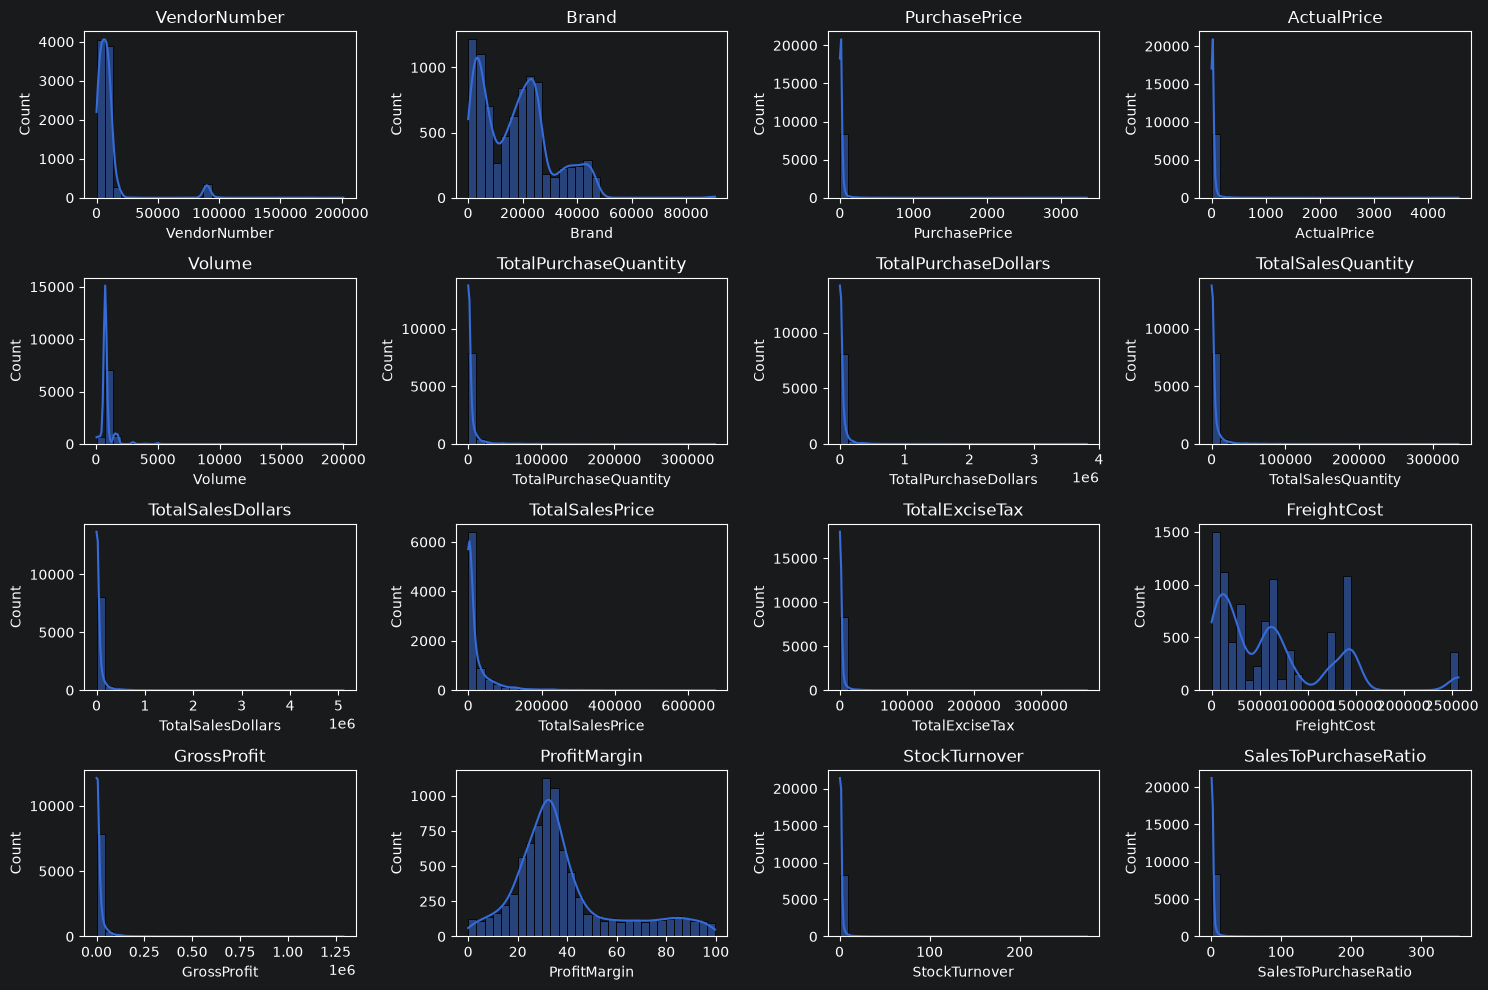

In [48]:
#Distribution Plots for Numerical Columns
numerical_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize =(15,10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)  # Adjust grid layout as needed
    sns.histplot(df[col],kde= True,bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()

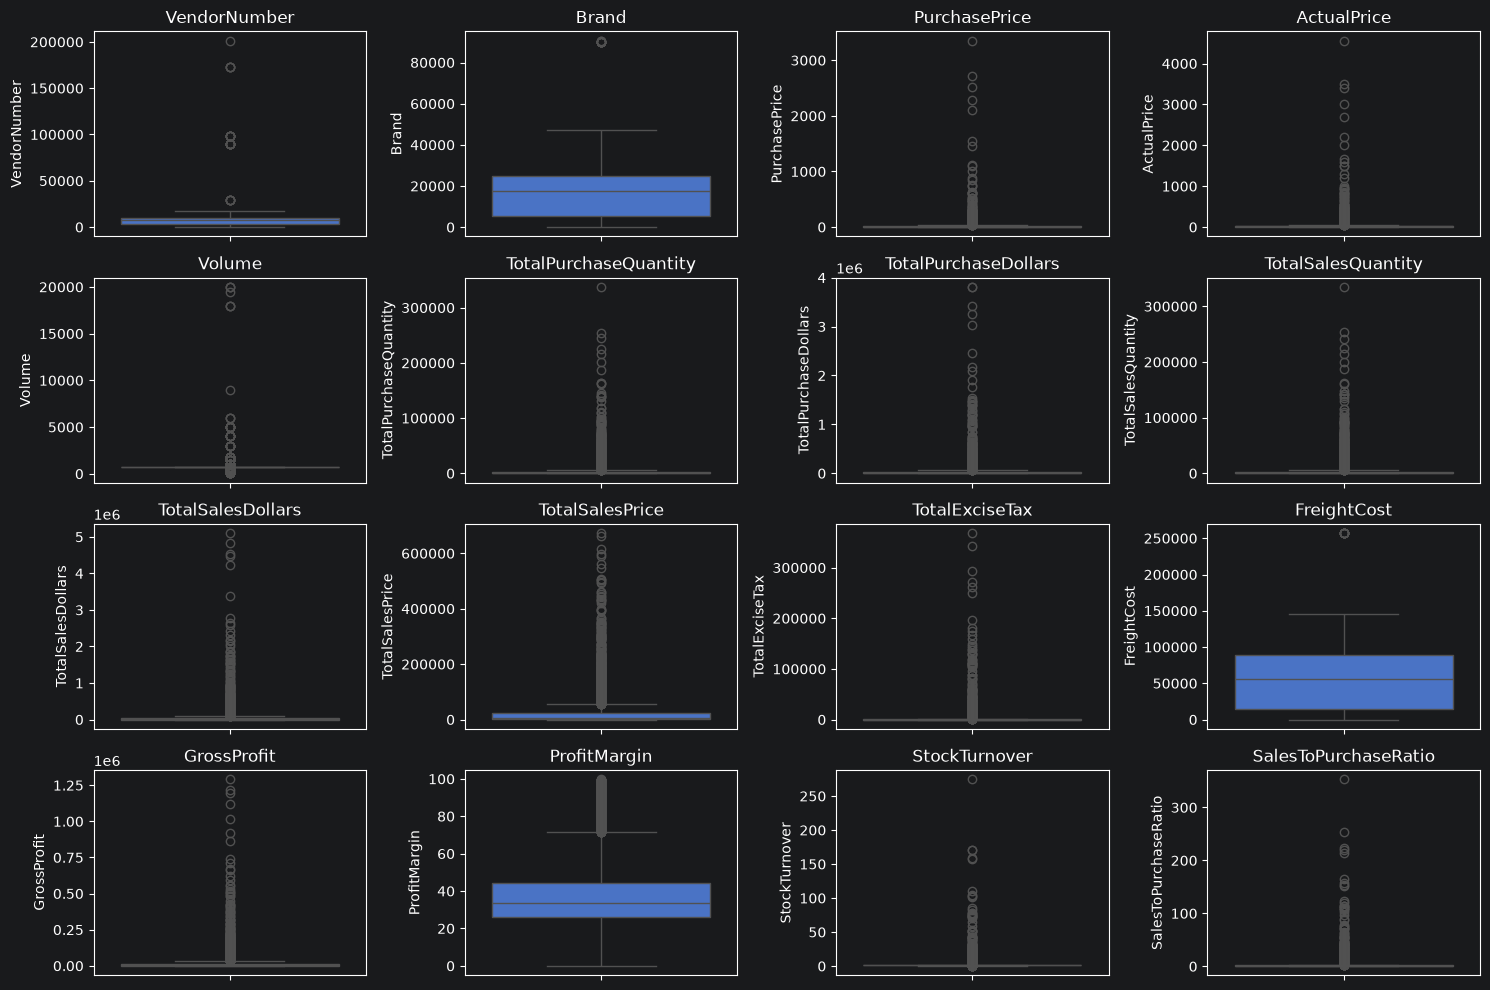

In [49]:
# Outlier Detection with Boxplots

plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)  # Subplot numbering starts from 1
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()   

In [75]:
# let`s filter the data by removing inconsistencies
df = pd.read_sql_query("""
    SELECT *
    FROM vendor_sales_summary
    WHERE GrossProfit > 0
      AND ProfitMargin > 0
      AND TotalSalesQuantity > 0
""", engine)
print(pd.read_sql_query(
    "PRAGMA table_info(vendor_sales_summary)",
    engine
))

    cid                   name    type  notnull dflt_value  pk
0     0           VendorNumber  BIGINT        0       None   0
1     1             VendorName    TEXT        0       None   0
2     2                  Brand  BIGINT        0       None   0
3     3            Description    TEXT        0       None   0
4     4          PurchasePrice   FLOAT        0       None   0
5     5            ActualPrice   FLOAT        0       None   0
6     6                 Volume   FLOAT        0       None   0
7     7  TotalPurchaseQuantity  BIGINT        0       None   0
8     8   TotalPurchaseDollars   FLOAT        0       None   0
9     9     TotalSalesQuantity   FLOAT        0       None   0
10   10      TotalSalesDollars   FLOAT        0       None   0
11   11        TotalSalesPrice   FLOAT        0       None   0
12   12         TotalExciseTax   FLOAT        0       None   0
13   13            FreightCost   FLOAT        0       None   0
14   14            GrossProfit   FLOAT        0       N

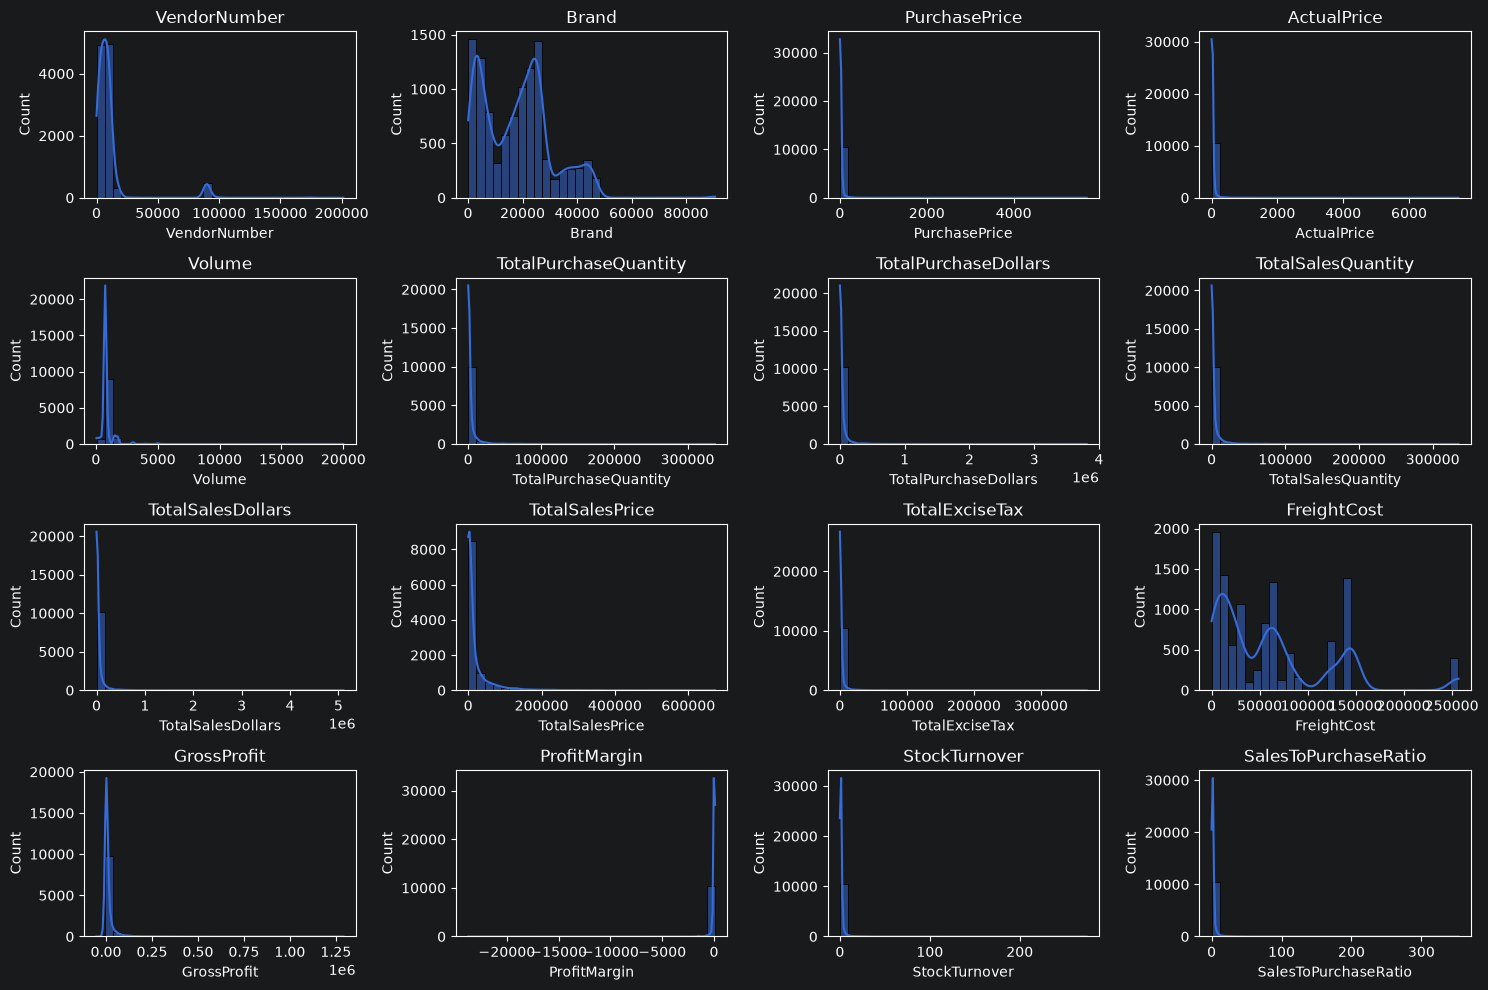

In [71]:
#Distribution Plots for Numerical Columns
numerical_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize =(15,10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)  # Adjust grid layout as needed
    sns.histplot(df[col],kde= True,bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()

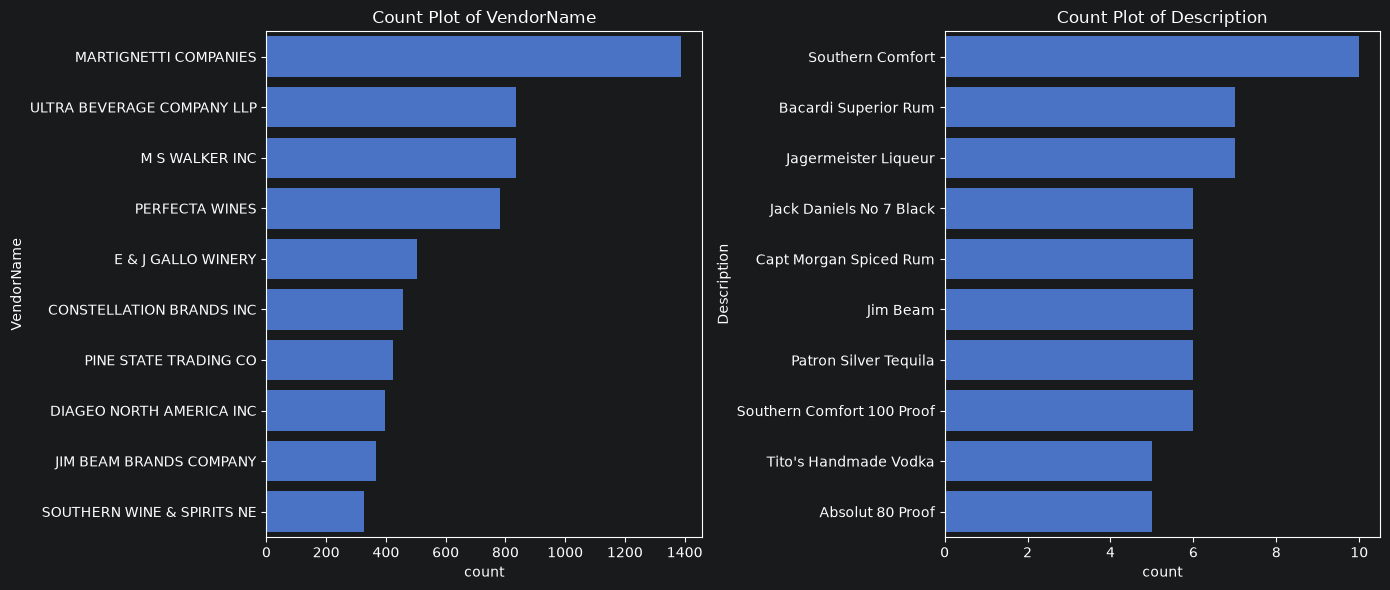

In [70]:
categorical_cols = ["VendorName","Description"]

plt.figure(figsize=(14,6))

for i, col in enumerate(categorical_cols):
    plt.subplot(1, 2, i + 1)

    sns.countplot(
        y=df[col],
        order=df[col].value_counts().head(10).index
    )

    plt.title(f"Count Plot of {col}")

plt.tight_layout()
plt.show()           

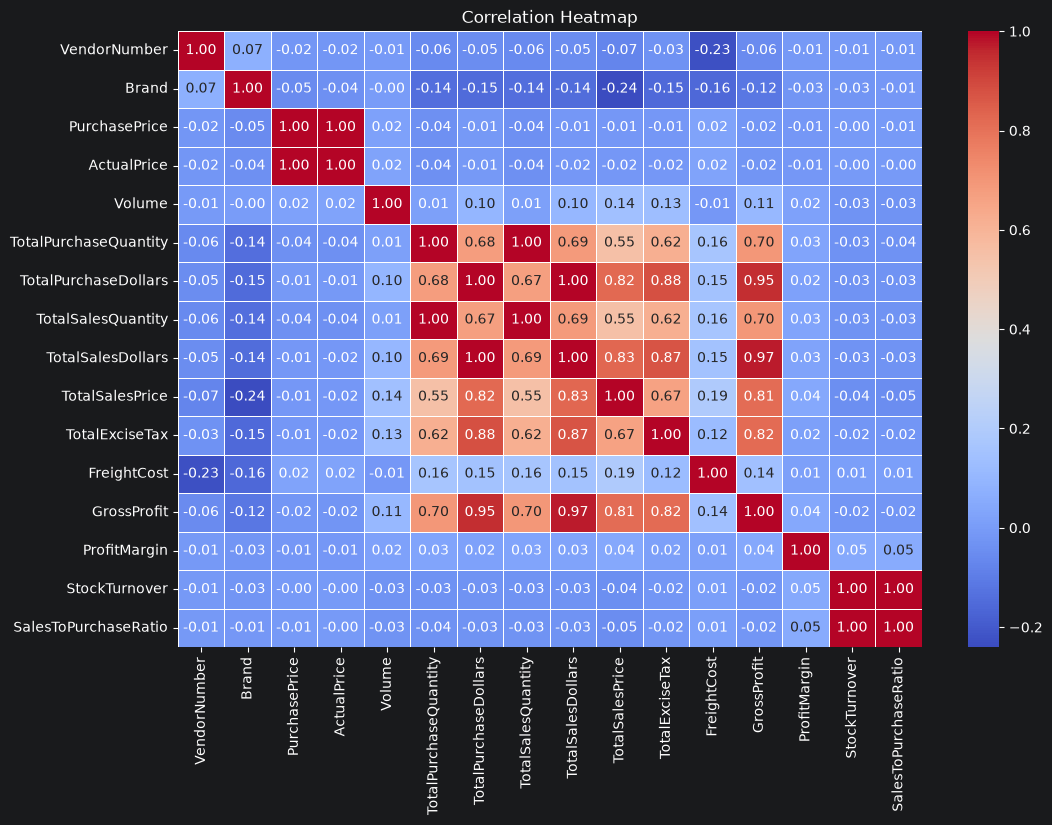

In [69]:
plt.figure(figsize =(12,8))
correlation_matrix=df[numerical_cols].corr()
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)
plt.title("Correlation Heatmap")
plt.show()

In [67]:
# Filter Brands with low sales but high profit margins
low_sales_threshold = brand_performance['TotalSalesDollars'].quantile(0.25)

high_margin_threshold = brand_performance['ProfitMargin'].quantile(0.75)

target_brands = brand_performance[
    (brand_performance['TotalSalesDollars'] <= low_sales_threshold) &
    (brand_performance['ProfitMargin'] >= high_margin_threshold)
]

print("Brands with Low Sales but High Profit Margins")
print(target_brands.sort_values('TotalSalesDollars'))

Brands with Low Sales but High Profit Margins
       Brand  TotalSalesDollars  TotalPurchaseDollars  GrossProfit  \
10399  44733           10012.67               6077.49      3935.18   
9888   39600           10054.28               6124.46      3929.82   
1627    3404           10058.93               3732.40      6326.53   
9421   34635           10190.24               6014.73      4175.51   
10110  42124           10199.85               5390.91      4808.94   
...      ...                ...                   ...          ...   
3371    8567           19428.20              11940.75      7487.45   
7596   24703           19432.84               9906.06      9526.78   
2880    6566           19490.49              10260.88      9229.61   
847     2050           19502.42              10566.93      8935.49   
5186   18332           19595.37              12002.76      7592.61   

       ProfitMargin  
10399     39.302004  
9888      39.086041  
1627      62.894662  
9421      40.975581  
101

In [65]:
brand_performance = (
df.groupby('Brand')
.agg({
'TotalSalesDollars': 'sum',
'TotalPurchaseDollars': 'sum',
'GrossProfit': 'sum',
'ProfitMargin': 'mean'
})
.reset_index()
)
brand_performance = brand_performance[
    brand_performance['TotalSalesDollars'] > 10000
]

print(brand_performance.shape)
brand_performance.head()

(4308, 5)


,Brand,TotalSalesDollars,TotalPurchaseDollars,GrossProfit,ProfitMargin
0,58,43341.54,32944.00,10397.54,23.989780
1,60,18716.25,12084.20,6632.05,35.434716
3,62,119863.75,91744.00,28119.75,23.459762
4,63,112249.22,86963.30,25285.92,22.526589
6,72,17325.31,11932.27,5393.04,31.128101


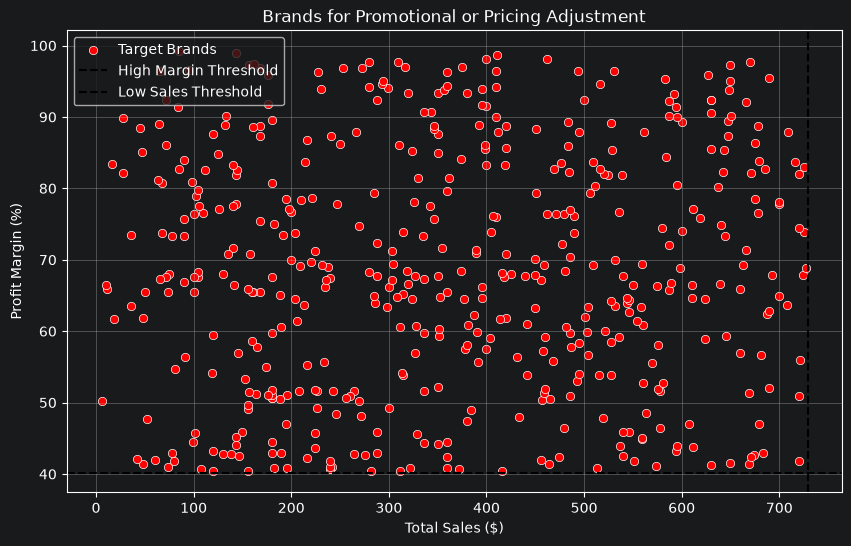

In [63]:
high_margin_threshold = df['ProfitMargin'].quantile(0.75)
low_sales_threshold = df['TotalSalesDollars'].quantile(0.25)

target_brands = df[
    (df['ProfitMargin'] >= high_margin_threshold) &
    (df['TotalSalesDollars'] <= low_sales_threshold)
]

plt.figure(figsize=(10, 6))
 
sns.scatterplot(
data=target_brands,
x='TotalSalesDollars',
y='ProfitMargin',
color='red',
label='Target Brands'
)
 
plt.axhline(
high_margin_threshold,
linestyle='--',
color='black',
label='High Margin Threshold'
)
 
plt.axvline(
low_sales_threshold,
linestyle='--',
color='black',
label='Low Sales Threshold'
)
 
plt.xlabel("Total Sales ($)")
plt.ylabel("Profit Margin (%)")
plt.title("Brands for Promotional or Pricing Adjustment")
plt.legend()
plt.grid(True)
 
plt.show()


In [58]:
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("sqlite:///inventory.db")

vendor_sales_summary = pd.read_sql_query(
    "SELECT * FROM vendor_sales_summary",
    engine
)

print(vendor_sales_summary.head())

top_vendors = (
    vendor_sales_summary
    .groupby("VendorName")["TotalSalesDollars"]
    .sum()
    .nlargest(10)
)

print(top_vendors)

df = pd.read_sql_query(
    "SELECT * FROM vendor_sales_summary",
    engine
)

print(df.shape)
print(df.columns)
# Top Vendors & Brands by Sales Performance
top_vendors = (
    df.groupby("VendorName")["TotalSalesDollars"]
    .sum()
    .nlargest(10)
)
top_brands = (
    df.groupby("Description")["TotalSalesDollars"]
    .sum()
    .nlargest(10)
)
top_vendors

   VendorNumber                VendorName  Brand              Description  \
0          1128         BROWN-FORMAN CORP   1233  Jack Daniels No 7 Black   
1          4425     MARTIGNETTI COMPANIES   3405    Tito's Handmade Vodka   
2         17035         PERNOD RICARD USA   8068         Absolut 80 Proof   
3          3960  DIAGEO NORTH AMERICA INC   4261   Capt Morgan Spiced Rum   
4          3960  DIAGEO NORTH AMERICA INC   3545          Ketel One Vodka   

   PurchasePrice  ActualPrice  Volume  TotalPurchaseQuantity  \
0          26.27        36.99  1750.0                 145080   
1          23.19        28.99  1750.0                 164038   
2          18.24        24.99  1750.0                 187407   
3          16.17        22.99  1750.0                 201682   
4          21.89        29.99  1750.0                 138109   

   TotalPurchaseDollars  TotalSalesQuantity  TotalSalesDollars  \
0            3811251.60            142049.0         5101919.51   
1            3804041

VendorName
DIAGEO NORTH AMERICA INC      68739834.97
MARTIGNETTI COMPANIES         40960117.82
PERNOD RICARD USA             32279544.17
JIM BEAM BRANDS COMPANY       31898621.16
BACARDI USA INC               25005365.79
CONSTELLATION BRANDS INC      24467134.23
E & J GALLO WINERY            18553774.66
BROWN-FORMAN CORP             18476611.60
ULTRA BEVERAGE COMPANY LLP    17802646.10
M S WALKER INC                15436066.26
Name: TotalSalesDollars, dtype: float64

In [57]:
def format_dollars(value):
    if value >= 1_000_000:
        return f"${value/1_000_000:.2f}M"
    elif value >= 1_000:
        return f"${value/1_000:.2f}K"
    else:
        return f"${value:.2f}"

top_brands.apply(format_dollars)

Brand
1233    $5.10M
3405    $4.82M
8068    $4.54M
4261    $4.48M
3545    $4.22M
3858    $3.38M
2589    $2.77M
3489    $2.64M
3102    $2.59M
1376    $2.44M
Name: TotalSalesDollars, dtype: str

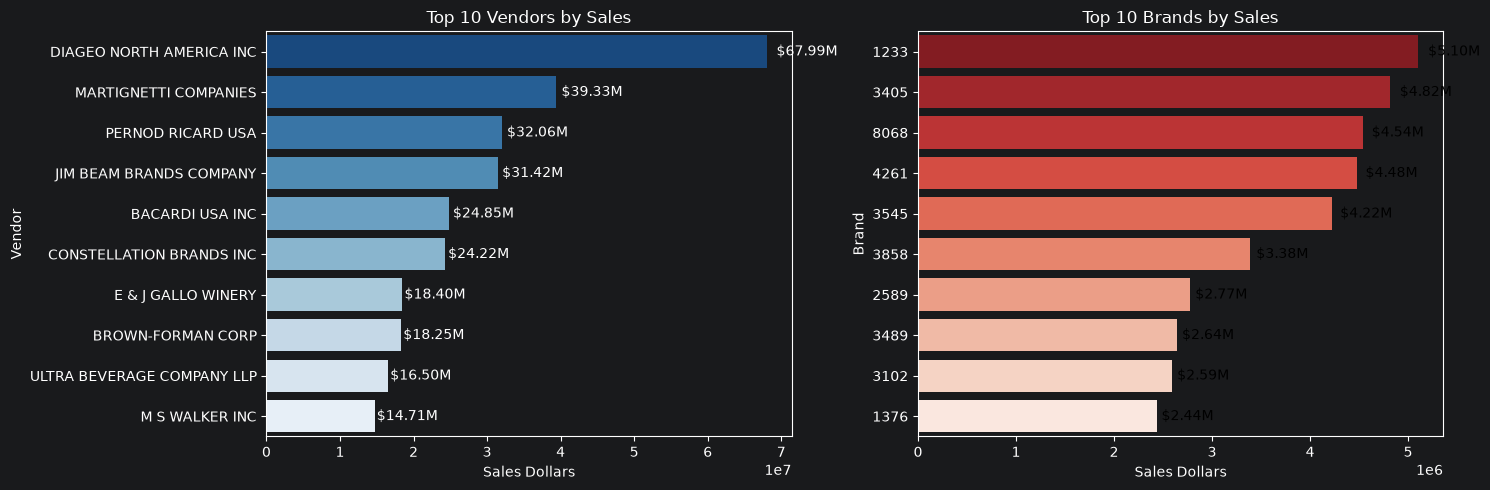

In [56]:
top_vendors = (
    df.groupby("VendorName")["TotalSalesDollars"]
      .sum()
      .nlargest(10)
)

top_brands = (
    df.groupby("Brand")["TotalSalesDollars"]
      .sum()
      .nlargest(10)
)

plt.figure(figsize=(15, 5))

# Plot for Top Vendors
plt.subplot(1, 2, 1)

ax1 = sns.barplot(
    y=top_vendors.index.astype(str),
    x=top_vendors.values,
    hue=top_vendors.index.astype(str),
    palette="Blues_r",
    legend=False
)

plt.title("Top 10 Vendors by Sales")
plt.xlabel("Sales Dollars")
plt.ylabel("Vendor")

for bar in ax1.patches:
    ax1.text(
        bar.get_width() + (bar.get_width() * 0.02),
        bar.get_y() + bar.get_height() / 2,
        format_dollars(bar.get_width()),
        ha="left",
        va="center"
    )

# Plot for Top Brands
plt.subplot(1, 2, 2)

ax2 = sns.barplot(
    y=top_brands.index.astype(str),
    x=top_brands.values,
    hue=top_brands.index.astype(str),
    palette="Reds_r",
    legend=False
)

plt.title("Top 10 Brands by Sales")
plt.xlabel("Sales Dollars")
plt.ylabel("Brand")

for bar in ax2.patches:
    ax2.text(
        bar.get_width() + (bar.get_width() * 0.02),
        bar.get_y() + bar.get_height() / 2,
        format_dollars(bar.get_width()),
        ha="left",
        va="center",
        fontsize=10,
        color="black"
    )

plt.tight_layout()
plt.show()

In [41]:
# Display Top 10 Vendors

vendor_performance = (
    df.groupby('VendorName')
      .agg({
          'TotalSalesDollars': 'sum',
          'TotalPurchaseDollars': 'sum',
          'GrossProfit': 'sum'
      })
      .reset_index()
      .sort_values('TotalSalesDollars', ascending=False)
)

vendor_performance = (
    df.groupby('VendorName', as_index=False)
      .agg({
          'TotalSalesDollars': 'sum',
          'TotalPurchaseDollars': 'sum',
          'GrossProfit': 'sum'
      })
      .sort_values('TotalSalesDollars', ascending=False)
)
# Keep numeric columns unchanged
top_vendors = vendor_performance.head(10).copy()

top_vendors_display = top_vendors.copy()

for col in [
    'TotalSalesDollars',
    'TotalPurchaseDollars',
    'GrossProfit'
]:
    top_vendors_display[col] = top_vendors_display[col].apply(format_dollars)

top_vendors_display

,VendorName,TotalSalesDollars,TotalPurchaseDollars,GrossProfit
28,DIAGEO NORTH AMERICA INC,$68.74M,$50.96M,$17.78M
63,MARTIGNETTI COMPANIES,$40.96M,$27.86M,$13.10M
74,PERNOD RICARD USA,$32.28M,$24.12M,$8.16M
50,JIM BEAM BRANDS COMPANY,$31.90M,$24.20M,$7.70M
8,BACARDI USA INC,$25.01M,$17.62M,$7.38M
23,CONSTELLATION BRANDS INC,$24.47M,$15.57M,$8.89M
33,E & J GALLO WINERY,$18.55M,$12.29M,$6.26M
14,BROWN-FORMAN CORP,$18.48M,$13.53M,$4.95M
114,ULTRA BEVERAGE COMPANY LLP,$17.80M,$13.21M,$4.59M
59,M S WALKER INC,$15.44M,$10.94M,$4.50M


In [39]:
top_vendors['PurchaseContribution%'].sum()

np.float64(65.3345754408899)

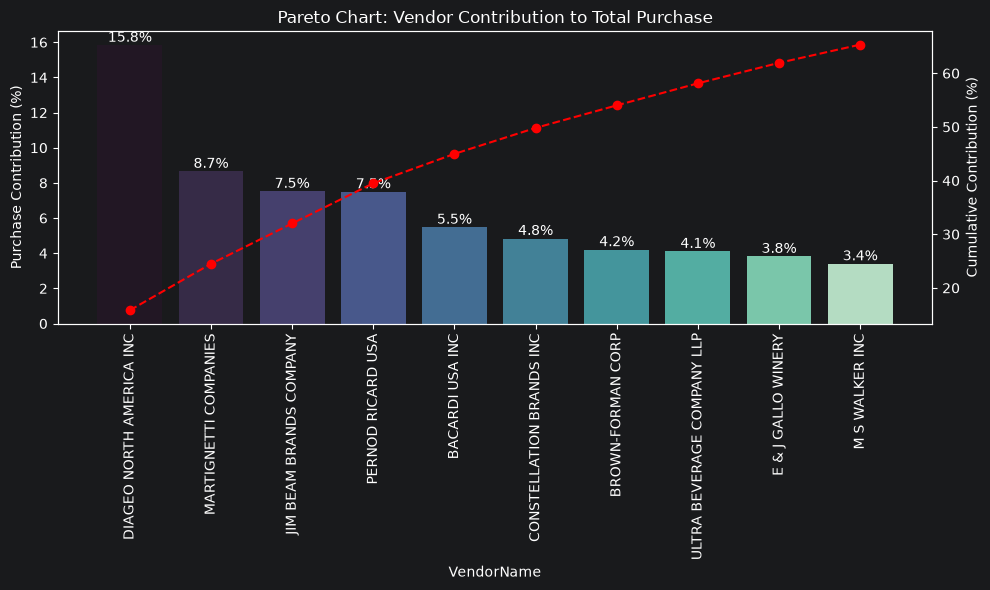

In [36]:
top_vendors = top_vendors.sort_values(
    'PurchaseContribution%',
    ascending=False
)

top_vendors['CumulativeContribution%'] = (
    top_vendors['PurchaseContribution%'].cumsum()
)
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar Plot
sns.barplot(
    data=top_vendors,
    x='VendorName',
    y='PurchaseContribution%',
    hue='VendorName',
    palette='mako',
    legend=False,
    ax=ax1
)

# Add labels
for i, value in enumerate(top_vendors['PurchaseContribution%']):
    ax1.text(
        i,
        value + 0.2,
        f"{value:.1f}%",
        ha='center',
        fontsize=10
    )

# Line Plot
ax2 = ax1.twinx()

ax2.plot(
    top_vendors['VendorName'],
    top_vendors['CumulativeContribution%'],
    color='red',
    marker='o',
    linestyle='dashed'
)

plt.setp(ax1.get_xticklabels(), rotation=90)

ax1.set_ylabel('Purchase Contribution (%)')
ax2.set_ylabel('Cumulative Contribution (%)')
ax1.set_title('Pareto Chart: Vendor Contribution to Total Purchase')

plt.tight_layout()
plt.show()


In [34]:
print(
    f"Total Purchase Contribution of Top 10 Vendors is "
    f"{top_vendors['PurchaseContribution%'].sum():.2f}%"
)

Total Purchase Contribution of Top 10 Vendors is 65.33%


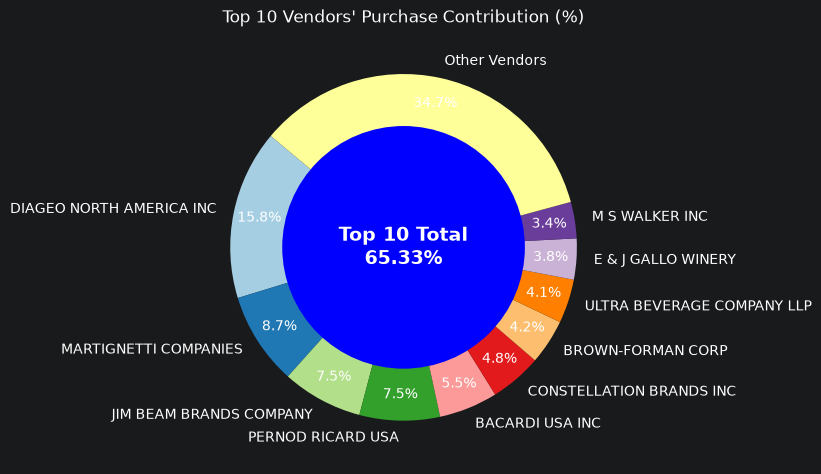

In [33]:
vendor_purchase = (
    df.groupby("VendorName")["TotalPurchaseDollars"]
      .sum()
      .reset_index()
)

total_purchase = vendor_purchase["TotalPurchaseDollars"].sum()

vendor_purchase["PurchaseContribution%"] = (
    vendor_purchase["TotalPurchaseDollars"] / total_purchase * 100
)

top_vendors = vendor_purchase.nlargest(
    10,
    "PurchaseContribution%"
)
# Extract top vendors and their contribution percentages
vendors = list(top_vendors['VendorName'].values)
purchase_contributions = list(top_vendors['PurchaseContribution%'].values)

# Calculate remaining contribution
total_contribution = sum(purchase_contributions)
remaining_contribution = 100 - total_contribution

# Append "Other Vendors"
vendors.append("Other Vendors")
purchase_contributions.append(remaining_contribution)

# Donut Chart
fig, ax = plt.subplots(figsize=(8, 8))

wedges, texts, autotexts = ax.pie(
    purchase_contributions,
    labels=vendors,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.85,
    colors=plt.cm.Paired.colors
)

# Draw white circle for donut effect
center_circle = plt.Circle((0, 0), 0.70, fc='Blue')
ax.add_artist(center_circle)

# Add total contribution annotation in the center
ax.text(
    0,
    0,
    f"Top 10 Total\n{total_contribution:.2f}%",
    fontsize=14,
    fontweight='bold',
    ha='center',
    va='center'
)

plt.title("Top 10 Vendors' Purchase Contribution (%)")
plt.tight_layout()
plt.show()

In [31]:
(
    df.groupby('OrderSize', observed=True)['UnitPurchasePrice']
      .agg(['mean', 'median', 'min', 'max'])
)

,mean,median,min,max
OrderSize,,,,
Small,43.776954,12.74,0.39,5681.81
Medium,17.894005,11.15,0.71,318.51
Large,11.308807,8.65,0.36,139.70


In [30]:
df.groupby("OrderSize", observed=True)["TotalPurchaseQuantity"].agg(
    ["min", "max", "mean", "count"]
)

,min,max,mean,count
OrderSize,,,,
Small,1,60,23.023969,3588
Medium,61,1038,359.247105,3541
Large,1039,337660,9045.090654,3563


In [28]:
print(df[['OrderSize', 'TotalPurchaseQuantity']].head(10))

  OrderSize  TotalPurchaseQuantity
0     Large                 145080
1     Large                 164038
2     Large                 187407
3     Large                 201682
4     Large                 138109
5     Large                 138809
6     Large                  70783
7     Large                 161386
8     Large                  91835
9     Large                 108866


In [26]:
order_size_analysis = (
    df.groupby('OrderSize', observed=True)['UnitPurchasePrice']
      .mean()
      .sort_values()
)

print(order_size_analysis)

OrderSize
Large     11.393655
Medium    17.719004
Small     40.062349
Name: UnitPurchasePrice, dtype: float64


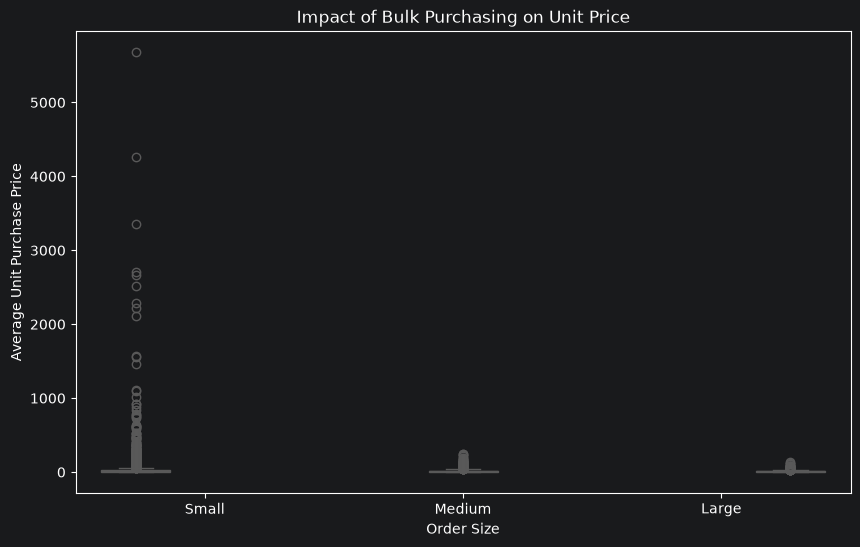

In [25]:
df["OrderSize"] = pd.cut(
    df["TotalPurchaseQuantity"],
    bins=[0, 100, 1000, float("inf")],
    labels=["Small", "Medium", "Large"]
)

df["UnitPurchasePrice"] = (
    df["TotalPurchaseDollars"] / df["TotalPurchaseQuantity"]
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="OrderSize",
    y="UnitPurchasePrice",
    hue="OrderSize",
    palette="Set2",
    legend=False
)

plt.title("Impact of Bulk Purchasing on Unit Price")
plt.xlabel("Order Size")
plt.ylabel("Average Unit Purchase Price")
plt.show()

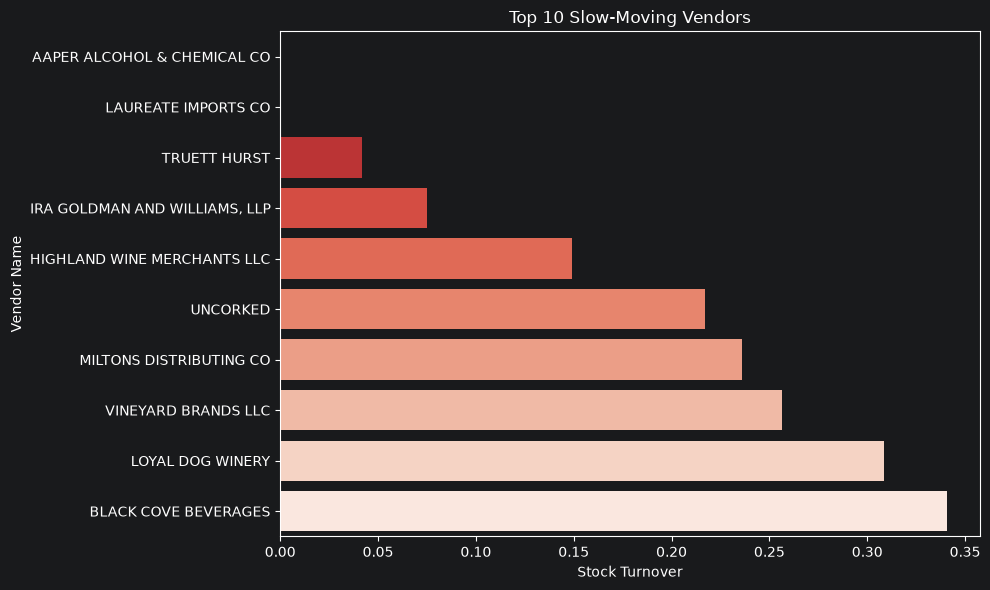

In [23]:
plot_df = (
    df[df['StockTurnover'] < 1]
    .groupby('VendorName')['StockTurnover']
    .mean()
    .sort_values()
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_df,
    x='StockTurnover',
    y='VendorName',
    hue='VendorName',
    palette='Reds_r',
    legend=False
)

plt.title('Top 10 Slow-Moving Vendors')
plt.xlabel('Stock Turnover')
plt.ylabel('Vendor Name')
plt.tight_layout()
plt.show()

In [22]:
# How much capital is locked in unsold inventory?

from sqlalchemy import create_engine
import pandas as pd

engine = create_engine("sqlite:///inventory.db")

df = pd.read_sql_query(
    "SELECT * FROM vendor_sales_summary",
    engine
)
def format_dollars(value):
    if value >= 1_000_000:
        return f"${value / 1_000_000:.2f}M"
    elif value >= 1_000:
        return f"${value / 1_000:.2f}K"
    else:
        return f"${value:.2f}"


df["UnsoldInventoryValue"] = (
    (df["TotalPurchaseQuantity"] - df["TotalSalesQuantity"])
    * df["PurchasePrice"]
)

print(
    "Total Unsold Capital:",
    format_dollars(df["UnsoldInventoryValue"].sum())
)


Total Unsold Capital: $8.75M


In [21]:
df["UnsoldQuantity"] = (
    df["TotalPurchaseQuantity"] - df["TotalSalesQuantity"]
)
df["UnsoldInventoryValue"] = (
    df["UnsoldQuantity"] * df["PurchasePrice"]
)
inventory_value_per_vendor = (
    df.groupby("VendorName")["UnsoldInventoryValue"]
    .sum()
    .reset_index()
)
def format_dollars(value):
    if pd.isna(value):
        return "0"

    if value >= 1_000_000:
        return f"${value / 1_000_000:.2f}M"
    elif value >= 1_000:
        return f"${value / 1_000:.2f}K"
    else:
        return f"${value:.2f}"

inventory_value_per_vendor["UnsoldInventoryValue"] = (
    inventory_value_per_vendor["UnsoldInventoryValue"]
    .apply(format_dollars)
)


# Aggregate Capital Locked Per Vendor
inventory_value_per_vendor = (
    df.groupby("VendorName")["UnsoldInventoryValue"]
      .sum()
      .reset_index()
)

# Sort vendors with highest locked capital
inventory_value_per_vendor = inventory_value_per_vendor.sort_values(
    by="UnsoldInventoryValue",
    ascending=False
)

# Format values
inventory_value_per_vendor["UnsoldInventoryValue"] = (
    inventory_value_per_vendor["UnsoldInventoryValue"]
    .apply(format_dollars)
)

# Top 10 vendors
inventory_value_per_vendor.head(10)

,VendorName,UnsoldInventoryValue
28,DIAGEO NORTH AMERICA INC,$980.09K
63,MARTIGNETTI COMPANIES,$928.99K
50,JIM BEAM BRANDS COMPANY,$857.80K
114,ULTRA BEVERAGE COMPANY LLP,$780.27K
73,PERFECTA WINES,$571.81K
74,PERNOD RICARD USA,$554.74K
59,M S WALKER INC,$469.96K
125,WILLIAM GRANT & SONS INC,$436.49K
33,E & J GALLO WINERY,$315.20K
14,BROWN-FORMAN CORP,$284.91K


In [ ]:
top_threshold = df["TotalSalesDollars"].quantile(0.75)
low_threshold = df["TotalSalesDollars"].quantile(0.25)

   VendorNumber                VendorName  Brand              Description  \
0          1128         BROWN-FORMAN CORP   1233  Jack Daniels No 7 Black   
1          4425     MARTIGNETTI COMPANIES   3405    Tito's Handmade Vodka   
2         17035         PERNOD RICARD USA   8068         Absolut 80 Proof   
3          3960  DIAGEO NORTH AMERICA INC   4261   Capt Morgan Spiced Rum   
4          3960  DIAGEO NORTH AMERICA INC   3545          Ketel One Vodka   

   PurchasePrice  ActualPrice  Volume  TotalPurchaseQuantity  \
0          26.27        36.99  1750.0                 145080   
1          23.19        28.99  1750.0                 164038   
2          18.24        24.99  1750.0                 187407   
3          16.17        22.99  1750.0                 201682   
4          21.89        29.99  1750.0                 138109   

   TotalPurchaseDollars  TotalSalesQuantity  TotalSalesDollars  \
0            3811251.60            142049.0         5101919.51   
1            3804041

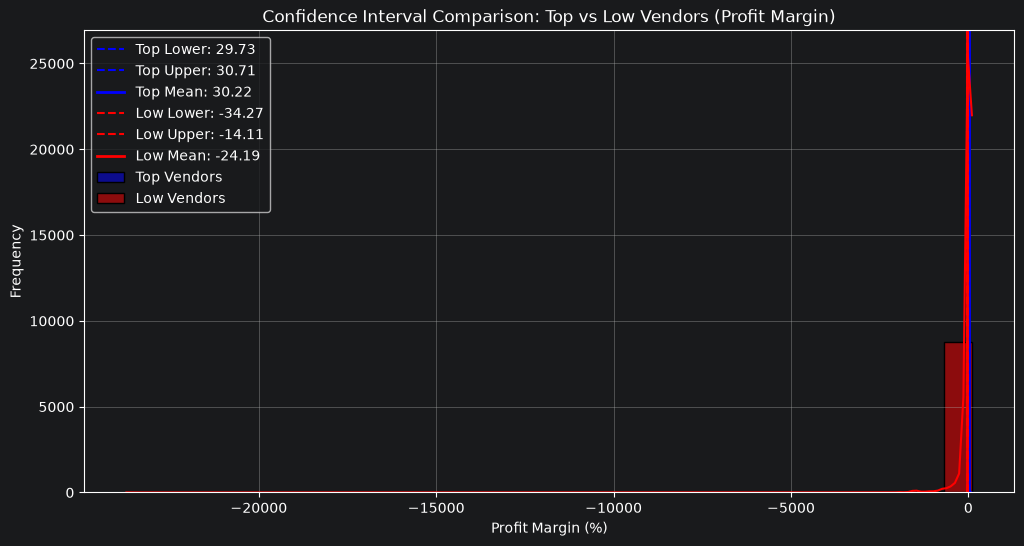

Index(['VendorNumber', 'VendorName', 'Brand', 'Description', 'PurchasePrice',
       'ActualPrice', 'Volume', 'TotalPurchaseQuantity',
       'TotalPurchaseDollars', 'TotalSalesQuantity', 'TotalSalesDollars',
       'TotalSalesPrice', 'TotalExciseTax', 'FreightCost', 'GrossProfit',
       'ProfitMargin', 'StockTurnover', 'SalesToPurchaseRatio'],
      dtype='str')


In [19]:
# Calculate confidence intervals

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

engine = create_engine("sqlite:///inventory.db")

df = pd.read_sql_query(
    "SELECT * FROM vendor_sales_summary",
    engine
)

print(df.head())

df.columns = (
df.columns
.str.strip()
.str.replace(" ", "", regex=False)
)
 
print(df.columns)

def confidence_interval(data, confidence=0.95):
    mean_val = np.mean(data)

    std_err = np.std(data, ddof=1) / np.sqrt(len(data))

    t_critical = stats.t.ppf(
        (1 + confidence) / 2,
        len(data) - 1
    )

    margin = t_critical * std_err

    lower = mean_val - margin
    upper = mean_val + margin

    return mean_val, lower, upper
     

top_threshold = df["TotalSalesDollars"].quantile(0.85)

top_vendors = df[df["TotalSalesDollars"] >= top_threshold]["ProfitMargin"].dropna()

low_vendors = df[df["TotalSalesDollars"] < top_threshold]["ProfitMargin"].dropna()

top_mean, top_lower, top_upper = confidence_interval(top_vendors)

low_mean, low_lower, low_upper = confidence_interval(low_vendors)

# Print results
print(
    f"Top Vendors 95% CI: ({top_lower:.2f}, {top_upper:.2f}), "
    f"Mean: {top_mean:.2f}"
)

print(
    f"Low Vendors 95% CI: ({low_lower:.2f}, {low_upper:.2f}), "
    f"Mean: {low_mean:.2f}"
)

# Plot distributions
plt.figure(figsize=(12, 6))

# Top Vendors Plot
sns.histplot(
    top_vendors,
    kde=True,
    color="blue",
    bins=30,
    alpha=0.5,
    label="Top Vendors"
)

plt.axvline(
    top_lower,
    color="blue",
    linestyle="--",
    label=f"Top Lower: {top_lower:.2f}"
)

plt.axvline(
    top_upper,
    color="blue",
    linestyle="--",
    label=f"Top Upper: {top_upper:.2f}"
)

plt.axvline(
    top_mean,
    color="blue",
    linestyle="-",
    linewidth=2,
    label=f"Top Mean: {top_mean:.2f}"
)

# Low Vendors Plot
sns.histplot(
    low_vendors,
    kde=True,
    color="red",
    bins=30,
    alpha=0.5,
    label="Low Vendors"
)

plt.axvline(
    low_lower,
    color="red",
    linestyle="--",
    label=f"Low Lower: {low_lower:.2f}"
)

plt.axvline(
    low_upper,
    color="red",
    linestyle="--",
    label=f"Low Upper: {low_upper:.2f}"
)

plt.axvline(
    low_mean,
    color="red",
    linestyle="-",
    linewidth=2,
    label=f"Low Mean: {low_mean:.2f}"
)

# Finalize Plot
plt.title("Confidence Interval Comparison: Top vs Low Vendors (Profit Margin)")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.show()

# Clean column names
df.columns = (
    df.columns
      .str.strip()
      .str.replace(" ", "", regex=False)
)

print(df.columns)